In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils import data
import numpy as np
import matplotlib.pyplot as plt
import torchvision
from torchvision import transforms
from PIL import Image

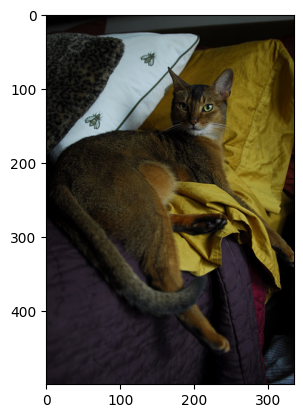

In [2]:
pilImg = Image.open(r'annotations/images/Abyssinian_14.jpg')
np_img = np.array(pilImg)
# np_img.shape
plt.imshow(np_img)

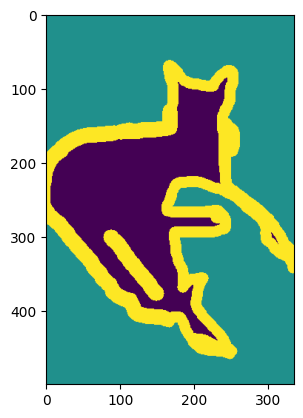

In [3]:
label_img = Image.open(r'annotations/trimaps/Abyssinian_14.png')
label_np_img = np.array(label_img)
# label_np_img
plt.imshow(label_np_img)

In [4]:
label_np_img.shape

(500, 335)

In [5]:
np.unique(label_np_img)

array([1, 2, 3], dtype=uint8)

In [6]:
import glob
#创建输入
images =glob.glob(r'annotations/images/*.jpg')
annotations = glob.glob(r'annotations/trimaps/*.png')
print(images[:5])
print(annotations[:5])

['annotations/images\\Abyssinian_1.jpg', 'annotations/images\\Abyssinian_10.jpg', 'annotations/images\\Abyssinian_100.jpg', 'annotations/images\\Abyssinian_101.jpg', 'annotations/images\\Abyssinian_102.jpg']
['annotations/trimaps\\Abyssinian_1.png', 'annotations/trimaps\\Abyssinian_10.png', 'annotations/trimaps\\Abyssinian_100.png', 'annotations/trimaps\\Abyssinian_101.png', 'annotations/trimaps\\Abyssinian_102.png']


In [7]:
len(images),len(annotations)

(7390, 7390)

In [8]:
# 打乱 数据集
np.random.seed(2023)
index = np.random.permutation(len(images))
images = np.array(images)[index]
annotations = np.array(annotations)[index]

In [9]:
# 80%数据训练，20%测试
sep = int(len(images)*0.8)
train_images = images[:sep]
train_labels = annotations[:sep]
test_images = images[sep:]
test_labels = annotations[sep:]

In [10]:
# 编写转换函数
transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor()
])

In [22]:
class Dataset(data.Dataset):
    def __init__(self,img_paths,anno_paths,transform):
        self.imgs=img_paths
        self.annos=anno_paths
        self.transform= transform
    def __getitem__(self,index):
        img = self.imgs[index]
        anno = self.annos[index]
        pil_img = Image.open(img)
        pil_img = pil_img.convert('RGB')
        img_tensor = transform(pil_img)

        pil_anno = Image.open(anno)
        pil_anno = pil_anno.resize((256,256))
        anno_tensor = torch.tensor(np.array(pil_anno),dtype = torch.int64)
        return img_tensor,anno_tensor-1     
    def __len__(self):
        return len(self.imgs)

In [23]:
train_dataset = Dataset(train_images,train_labels,transform)
test_dataset = Dataset(test_images,test_labels,transform)

In [24]:
BATCH_SIZE = 16
# 数据加载器
train_dl = torch.utils.data.DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True
)
test_dl = torch.utils.data.DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE
)

In [25]:
# 创建u-net下采集模型
class Downsample(nn.Module):
    def __init__(self,in_channels,out_channels):
        super(Downsample,self).__init__()
        self.conv_relu = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels,out_channels,kernel_size=3,padding=1),
            nn.ReLU(inplace=True)
        )
        self.pool = nn.MaxPool2d(kernel_size=2)
    def forward(self,x,is_pool=True):
        if is_pool:
            x = self.pool(x)
        x = self.conv_relu(x)
        return x

In [26]:
# 创建u-net上采集模型
class Upsampler(nn.Module):
    def __init__(self,channels):
        super(Upsampler,self).__init__()
        self.conv_relu = nn.Sequential(
            nn.Conv2d(channels*2,channels,kernel_size=3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels,channels,kernel_size=3,padding=1),
            nn.ReLU(inplace=True)
        )

        # 转置卷积层，增加数据空间的维度
        self.upconv_relu = nn.Sequential(
            nn.ConvTranspose2d(
                # 输入特征的通道数
                channels,
                # 输入特征的通道数
                channels//2,
                # 卷积核大小
                kernel_size = 3,
                # 卷积步长
                stride=2,
                padding=1,
                # 输入特征图额外填充
                output_padding=1
                
            ),
            nn.ReLU(inplace=True)
        )

    def forward(self,x):
        x = self.conv_relu(x)
        x = self.upconv_relu(x)
        return x        
        

In [36]:
class UNet(nn.Module):
    def __init__(self):
        super(UNet,self).__init__()
        self.down1=Downsample(3,64)
        self.down2=Downsample(64,128)
        self.down3=Downsample(128,256)
        self.down4=Downsample(256,512)
        self.down5=Downsample(512,1024)

        self.up = nn.Sequential(
            nn.ConvTranspose2d(
                # 输入特征的通道数
                1024,
                # 输入特征的通道数
                512,
                # 卷积核大小
                kernel_size = 3,
                # 卷积步长
                stride=2,
                padding=1,
                # 输入特征图额外填充
                output_padding=1
                
            ),
            nn.ReLU(inplace=True)
            
        )

        self.up1 = Upsampler(512)
        self.up2 = Upsampler(256)
        self.up3 = Upsampler(128)

        self.conv_2 = Downsample(128,64)
        self.last = nn.Conv2d(64,3,kernel_size=1)
    def forward(self,x):
        # input:16*(3*512*512) ->output:16（64*512*512）
        x1 = self.down1(x,is_pool=False)
        # 64*512*512->池化maxpool->64*256*256 ->卷积 ->128*256*256
        x2 = self.down2(x1)
        # 128*256*256->池化maxpool->128*128*128 ->卷积 -> 256*128*128
        x3 = self.down3(x2)
        # 256*128*128->池化maxpool->256*64*64 ->卷积 -> 512*64*64
        x4= self.down4(x3)
        # 512*64*64->池化maxpool->512*32*32 ->卷积 -> 1024*32*32
        x5= self.down5(x4)

        # 1024*32*32 -> 转置 ->512*64*64
        x5 = self.up(x5)
        
        # dim表示一维
        # 16*（512*64*64）+16*（512*64*64）=16*（1024*64*64）
        x5 = torch.cat([x4,x5],dim=1)
        # 1024*64*64 ->卷积 -> 512*64*64 ->转置 ->256*128*128
        x5 = self.up1(x5)
        # 256*128*128+256*128*128=512*128*128
        x5 = torch.cat([x3,x5],dim=1)
        # 512*128*128  ->256*128*128  ->128*256*256
        x5 = self.up2(x5)
        # 128*256*256 *2 = 256*256*256
        x5 = torch.cat([x2,x5],dim=1)
        # 256*256*256 ->128*256*256 ->64*512*512
        x5 = self.up3(x5)
        # 64*512*512*2=128*512*512
        x5 = torch.cat([x1,x5],dim=1)
        # 128*512*512 -> 卷积 ->64*512*512
        x5 = self.conv_2(x5,is_pool=False)
        # 64*512*512 ->卷积kernelsize：1 ->3*512*512
        x5 = self.last(x5)
        return x5

        

In [37]:
model = UNet()

In [38]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
device

'cuda'

In [39]:
model

UNet(
  (down1): Downsample(
    (conv_relu): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (down2): Downsample(
    (conv_relu): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (down3): Downsample(
    (conv_relu): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=Tr

In [40]:
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor([2,1,3],dtype=torch.float32).to(device))
optimizer=torch.optim.Adam(model.parameters(),lr=0.0005)

In [41]:
# 定义训练函数，从训练加载器里提取训练数据，进行训练
def train(dataLoader,model,loss_fn,optimizer):
    # 获取整个训练数据集大小
    size = len(dataLoader.dataset)
    train_loss,correct=0,0      
    # 循环遍历整个数据集
    for X,Y in dataLoader:
        X,Y=X.to(device),Y.to(device)
        # 进行初步预测
        pred=model(X)
        # 查看误差
        loss = loss_fn(pred,Y)

        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 使用优化器更新参数
        optimizer.step()

        # 计算当前准确率
        # 计算准确率不需要更新梯度
        with torch.no_grad():
            pred = torch.argmax(pred,dim=1)
            # 在10个数据里挑最大值
            correct += (pred==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/(size*256*256)
    return train_loss,correct
        

In [44]:
# 定义一个测试函数
def test(dataLoader,model):
    # 获取测试集大小
    size = len(dataLoader.dataset)
    train_loss, correct = 0, 0
     # 计算准确率不需要更新梯度
    with torch.no_grad():
        for X,Y in dataLoader:
            X,Y=X.to(device),Y.to(device)
            # 进行初步预测
            pred=model(X)
            # 查看误差
            loss = loss_fn(pred,Y)
            
            pred = torch.argmax(pred,dim=1)
            # 在10个数据里挑最大值
            correct += (pred==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/(size*256*256)
    return train_loss,correct

In [45]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]
train_loss=[]
test_loss=[]

# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model,loss_fn,optimizer)
    epoch_test_loss,epoch_test_acc = test(test_dl,model)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    train_loss.append(epoch_loss)
    test_loss.append(epoch_test_loss)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型',epoch_test_acc)
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存模型结构，包含参数
        torch.save(model,'best_model.pth')
        # 保存参数
        # torch.save(model1.state_dict(),'best_model_weights'+str(best_acc_index)+'.pth')

epoch:0,train_loss:0.04921433236828031,train_acc0.7028321897225387
epoch:0,test_loss:0.0459014422919334,test_acc0.7197499565568442
---------------------------------
保存最佳准确率模型 0.7197499565568442
epoch:1,train_loss:0.041267461328690365,train_acc0.753307956803958
epoch:1,test_loss:0.036547536920146145,test_acc0.7876113148277603
---------------------------------
保存最佳准确率模型 0.7876113148277603
epoch:2,train_loss:0.03410797288921109,train_acc0.8056618686619244
epoch:2,test_loss:0.033805983173831065,test_acc0.7963847881724935
---------------------------------
保存最佳准确率模型 0.7963847881724935
epoch:3,train_loss:0.03028449718619877,train_acc0.8291241383842912
epoch:3,test_loss:0.030852075439344723,test_acc0.8089817754309296
---------------------------------
保存最佳准确率模型 0.8089817754309296
epoch:4,train_loss:0.027872268080267756,train_acc0.8449111649406134
epoch:4,test_loss:0.02922912071054456,test_acc0.8352534561260466
---------------------------------
保存最佳准确率模型 0.8352534561260466
epoch:5,train_loss:0.0

In [51]:
model2 = torch.load('best_model.pth')
model2 = model2.to('cpu')

C:\Users\rehuanoo\AppData\Local\Temp\ipykernel_25972\3265041590.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model2 = torch.load('best_model.pth')


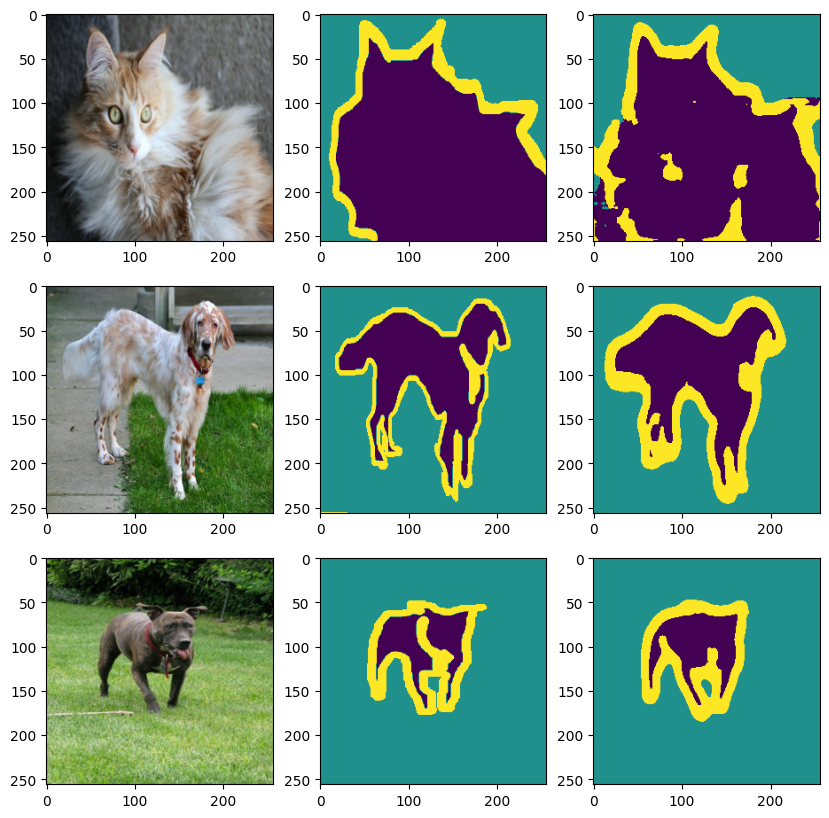

In [52]:
# 测试模型
# 加载模型，设置模型为评估模式，model.eval()

num =3
image,mask=next(iter(test_dl))
pred_mask = model2(image)

plt.figure(figsize=(10,10))
for i in range(num):
    plt.subplot(num,3,i*num+1)
    plt.imshow(image[i].permute(1,2,0).cpu().numpy())
    plt.subplot(num,3,i*num+2)
    plt.imshow(mask[i].cpu().numpy())
    plt.subplot(num,3,i*num+3)
    preData = torch.squeeze(pred_mask[i].argmax(0)).detach().numpy()
    plt.imshow(preData)